# 02 - Prétraitement

Mise en œuvre et vérification des choix justifiés dans `01-eda` (code dans `src/load_data.py`).

Pipeline appliqué à **chaque** image, à l'entraînement comme dans l'application :
1. conversion en niveaux de gris (1 canal)
2. recadrage sur le cerveau
3. redimensionnement à 224×224 sans déformation (bandes noires si l'image n'est pas carrée)
4. passage en [0, 1] puis standardisation de chaque image (sa moyenne, son écart-type)

In [1]:
# eviter le reload de kernel

%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")

from load_data import (CLASS_NAMES, crop_brain, list_images, load_brain_tumor_data,
                        prepare_image, prepare_dataset, MRIDataset, get_dataloaders)
from utils import load_config


## 1. Le pipeline, étape par étape

C:\Users\araba\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


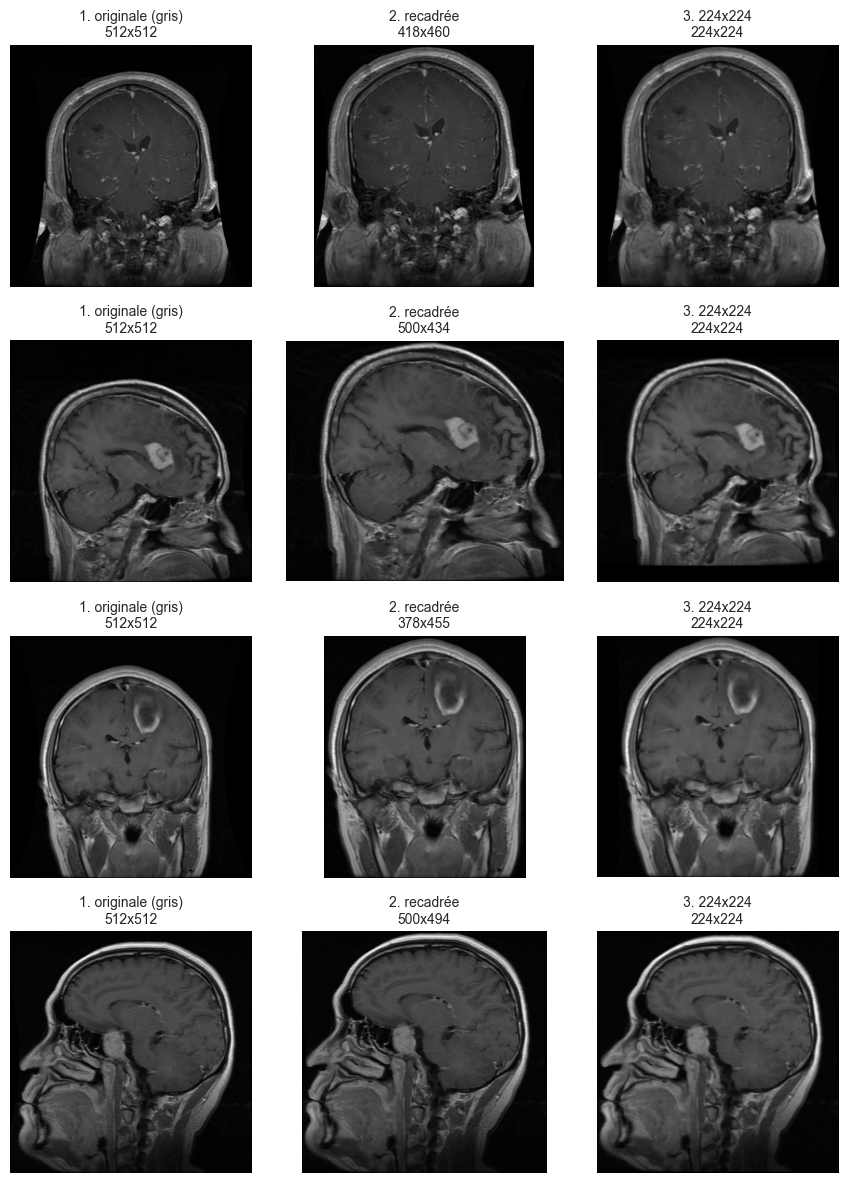

In [3]:
cfg = load_config()["project"]
SIZE = cfg["image_size"]
DATA = load_brain_tumor_data()
paths, labels = list_images(DATA, "Training")

rng = np.random.default_rng(3)
examples = [paths[i] for i in rng.choice(len(paths), 4, replace=False)]
fig, axes = plt.subplots(4, 3, figsize=(9, 12))
for r, p in enumerate(examples):
    gray = np.asarray(Image.open(p).convert("L"))
    cropped = crop_brain(gray)
    final = prepare_image(p, SIZE)
    steps = [(gray, "1. originale (gris)"), (cropped, "2. recadrée"), (final, f"3. {SIZE}x{SIZE}")]
    for c, (img, title) in enumerate(steps):
        axes[r, c].imshow(img, cmap="gray"); axes[r, c].axis("off")
        axes[r, c].set_title(f"{title}\n{img.shape[1]}x{img.shape[0]}", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "preproc_steps.png", dpi=150); plt.show()

## 2. Quasi-doublons

Le MD5 (notebook 01) ne trouve que les fichiers identiques. Ici, toutes les images ont la même taille, on peut donc les comparer directement : on réduit chaque image en 32x32 et on mesure l'écart moyen entre pixels (0 = identiques, 1 = opposées). On compare chaque image de Training à son image la plus proche dans Testing.

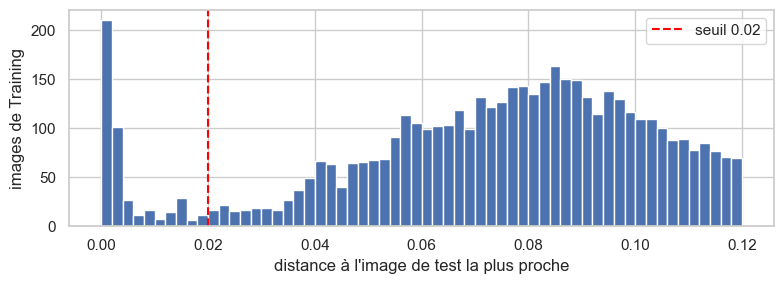

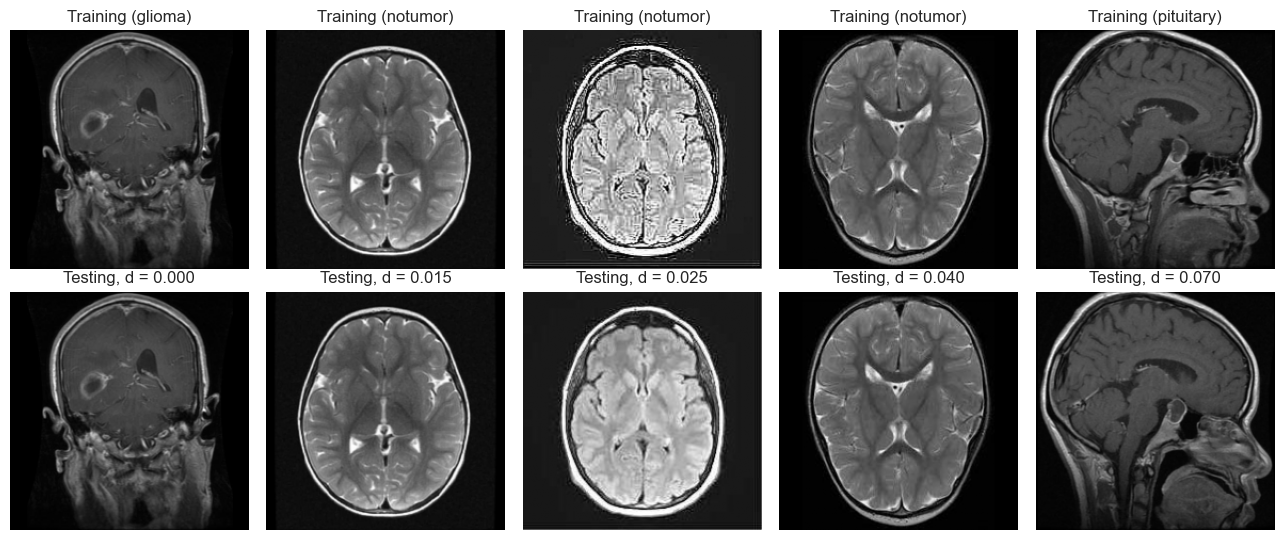

images de Training qui ont une copie dans Testing : 433 sur 5600


notumor       323
meningioma    106
glioma          4
Name: count, dtype: int64

In [4]:
import torch
from load_data import near_duplicates

tr_paths, tr_y = list_images(DATA, "Training")
te_paths, te_y = list_images(DATA, "Testing")
x_tr = np.stack([prepare_image(p, SIZE) for p in tr_paths])
x_te = np.stack([prepare_image(p, SIZE) for p in te_paths])

def thumbs(a):
    return torch.nn.functional.adaptive_avg_pool2d(torch.from_numpy(a).float().unsqueeze(1) / 255, 32).flatten(1)

dist, nearest = (torch.cdist(thumbs(x_tr), thumbs(x_te)) / 32).min(dim=1)
dist, nearest = dist.numpy(), nearest.numpy()

plt.figure(figsize=(8, 3))
plt.hist(dist, bins=np.linspace(0, 0.12, 61)); plt.axvline(0.02, color="red", ls="--", label="seuil 0.02")
plt.xlabel("distance à l'image de test la plus proche"); plt.ylabel("images de Training"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "preproc_near_dup_hist.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for k, target in enumerate([0.0, 0.015, 0.025, 0.04, 0.07]):
    i = int(np.abs(dist - target).argmin())
    axes[0, k].imshow(x_tr[i], cmap="gray"); axes[0, k].set_title(f"Training ({CLASS_NAMES[tr_y[i]]})")
    axes[1, k].imshow(x_te[nearest[i]], cmap="gray"); axes[1, k].set_title(f"Testing, d = {dist[i]:.3f}")
for a in axes.flat:
    a.axis("off")
plt.tight_layout(); plt.savefig(FIG / "preproc_near_dup_pairs.png", dpi=150); plt.show()

near = dist < 0.02
print(f"images de Training qui ont une copie dans Testing : {near.sum()} sur {len(near)}")
pd.Series(np.array(CLASS_NAMES)[tr_y[near]]).value_counts()

- En dessous de **0.02**, c'est la **même image** (juste enregistrée à une autre taille ou compression). Vers 0.025, on trouve encore parfois la même image avec un contraste retouché ; au-delà, ce sont des coupes voisines ou d'autres patients. Le seuil 0.02 est **prudent** : il ne retire que des copies sûres, quelques versions retouchées peuvent rester (voir limites).
- Plus de 400 images de Training sont des copies d'images du test, surtout en notumor. Si on les garde, le modèle a « déjà vu » une partie du test et le score de test est faussé.
- Choix : on retire de Training ces copies, puis les quasi-doublons internes à Training (sinon fuite entre train et validation). On ne touche pas au test officiel.

C'est fait dans `prepare_dataset` avec la fonction `near_duplicates`.

## 3. Préparation complète + découpage train / validation / test
Le résultat (images 224×224 en `uint8`) est mis en cache dans `data/processed/`, ce qui évite de relire et redimensionner les JPEG à chaque epoch.

In [5]:
data = prepare_dataset(SIZE, cfg["val_size"], cfg["seed"])
s = data.stats
print(f"Training brut : {s['n_train_raw']} images")
print(f"retirés : {s['n_duplicates_removed']} doublons exacts, "
      f"{s['n_near_test_removed']} copies d'images du test, "
      f"{s['n_near_duplicates_removed']} quasi-doublons internes")
split_df = pd.DataFrame({
    name: pd.Series(y).map(dict(enumerate(CLASS_NAMES))).value_counts()
    for name, y in [("train", data.y_train), ("validation", data.y_val), ("test", data.y_test)]
}).loc[CLASS_NAMES]
split_df.loc["Total"] = split_df.sum()
split_df

Training brut : 5600 images
retirés : 171 doublons exacts, 407 copies d'images du test, 223 quasi-doublons internes


,train,validation,test
glioma,1186,209,400
meningioma,1091,193,400
notumor,650,115,400
pituitary,1152,203,400
Total,4079,720,1600


Le découpage est **stratifié** : chaque classe garde la même proportion dans train et validation.
- **train** : apprentissage des poids
- **validation** : callbacks (early stopping, sauvegarde du meilleur modèle) et optimisation des hyperparamètres
- **test** : utilisé **une seule fois**, pour l'évaluation finale (étape 4). Ne jamais l'utiliser pour choisir un modèle, sinon le score de test devient optimiste.

Après le nettoyage, les classes ne sont plus équilibrées : notumor a environ deux fois moins d'images que les autres. On a testé une loss pondérée par classe : même accuracy de validation (96,0 %) avec ou sans, donc on ne l'a pas gardée. On surveille quand même le rappel de chaque classe à l'évaluation.

## 4. Normalisation

,avant (0-255),après
glioma,43.16,-0.0
meningioma,53.02,-0.0
notumor,63.08,-0.0
pituitary,52.74,-0.0


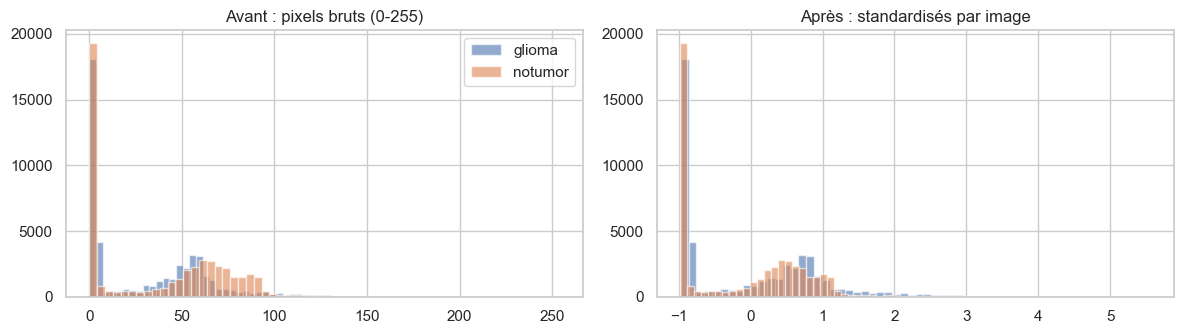

In [6]:
import torch
from load_data import normalize

# luminosité moyenne par classe, avant et après normalisation
x = torch.from_numpy(data.x_train)
avant = [x[data.y_train == k].float().mean().item() for k in range(4)]
apres = [torch.stack([normalize(img) for img in x[data.y_train == k][:200]]).mean().item() for k in range(4)]
display(pd.DataFrame({"avant (0-255)": avant, "après": apres}, index=CLASS_NAMES).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for k in [0, 2]:  # un glioma (sombre) et un notumor (clair)
    img = x[data.y_train == k][0]
    axes[0].hist(img.numpy().ravel(), bins=60, alpha=0.6, label=CLASS_NAMES[k])
    axes[1].hist(normalize(img).numpy().ravel(), bins=60, alpha=0.6, label=CLASS_NAMES[k])
axes[0].set_title("Avant : pixels bruts (0-255)"); axes[1].set_title("Après : standardisés par image")
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG / "preproc_normalization.png", dpi=150); plt.show()

Chaque image est standardisée avec **sa propre** moyenne et **son propre** écart-type : après ça, toutes les images ont une moyenne de 0 et un écart-type de 1.

Pourquoi par image et pas avec les statistiques du train ? Dans l'EDA, les notumor sont plus claires que les autres classes (elles viennent d'une autre source). Avec une normalisation globale, cette différence reste visible et le modèle s'en sert pour reconnaître notumor sans regarder le cerveau. Avec une normalisation par image, elle disparaît (tableau ci-dessus).

On a comparé les deux sur la validation : 93,8 % avec la normalisation globale, 95,3 % par image (voir notebook 03).

Autre avantage : pas de statistique à enregistrer, l'application applique le même calcul à n'importe quelle image.

## 5. Augmentation de données (train uniquement)

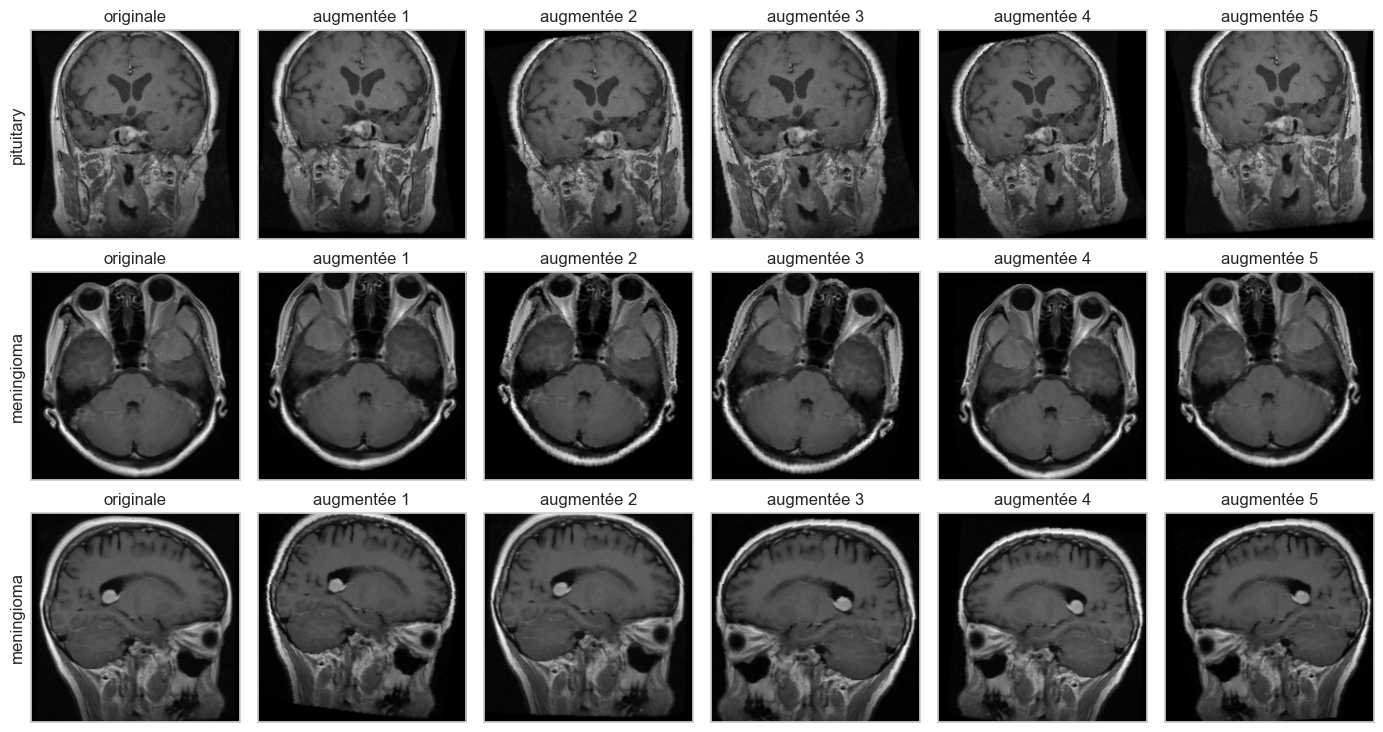

In [7]:
aug = MRIDataset(data.x_train, data.y_train, augment=True)
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for r, i in enumerate([0, 7, 42]):
    axes[r, 0].imshow(data.x_train[i], cmap="gray"); axes[r, 0].set_title("originale")
    for c in range(1, 6):
        x, _ = aug[i]
        axes[r, c].imshow(x[0], cmap="gray"); axes[r, c].set_title(f"augmentée {c}")
    axes[r, 0].set_ylabel(CLASS_NAMES[data.y_train[i]], fontsize=12)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "preproc_augmentation.png", dpi=150); plt.show()

Augmentations **légères et réalistes** pour une IRM, tirées au hasard à chaque epoch :
- **flip horizontal** : le cerveau est à peu près symétrique gauche/droite, une tumeur peut être d'un côté comme de l'autre (pas de flip vertical : une IRM « à l'envers » n'existe pas)
- **rotation ±10°, translation ±5 %, zoom ±5 %** : variations de position du patient
- **luminosité / contraste ±10 %** : variations entre machines et séquences

Elles augmentent artificiellement la diversité du train et **limitent le surapprentissage**. Elles ne sont **jamais** appliquées à la validation ni au test.

On n'a pas ajouté de rehaussement (CLAHE, débruitage, égalisation d'histogramme) : les images sont déjà nettes, et le CNN apprend lui-même à gérer le contraste.

## 6. Vérification des DataLoaders

In [8]:
train_loader, val_loader, test_loader = get_dataloaders(data, batch_size=32)
x, y = next(iter(train_loader))
print("batch :", tuple(x.shape), x.dtype, "| labels :", y[:10].tolist())
print(f"moyenne du batch = {x.mean():.3f}, écart-type = {x.std():.3f}")
print("batches :", len(train_loader), "train,", len(val_loader), "val,", len(test_loader), "test")

batch : (32, 1, 224, 224) torch.float32 | labels : [0, 1, 3, 1, 1, 3, 0, 1, 0, 0]
moyenne du batch = -0.000, écart-type = 1.000
batches : 128 train, 23 val, 50 test


## Bilan

Les données sont prêtes pour le modèle (étape 2) :
- entrées de forme **(batch, 1, 224, 224)**, standardisées image par image
- 4 classes dans l'ordre `glioma, meningioma, notumor, pituitary` (indices 0 à 3)
- train / validation / test séparés, sans doublon ni copie entre eux (vérifié dans `tests/test_data_integrity.py`)
- classes un peu déséquilibrées après nettoyage : on suit le rappel de chaque classe

Pour l'application : `load_data.preprocess_for_inference(image_pil, stats)` applique exactement ce pipeline à une nouvelle image.